# Reduced-Scale Spiking GNW Tuning: RTM–WB and FLN

This notebook has a reduced-network tuning mode to make parameter experiments faster. It keeps V4, V4's five strongest direct FLN targets (V2, MT, V1, TEO, DP), and the six selected workspace areas (F1, F2, F3, F4, 7a, 7b): 12 areas total. Each selected area retains four RTM cells and 40 WB cells, preserving the local circuit size while reducing the number of simulated areas.

The FLN weights are normalized using the full anatomical network before selecting the 12-area subnetwork. Inputs from omitted areas are therefore absent rather than redistributed onto the retained areas. This is a tuning approximation; after choosing parameters, switch back to all 40 areas and rerun validation.

The reduced run uses a 600 ms simulation with the V4 pulse ending at 500 ms, leaving 100 ms to inspect post-stimulus activity. Parameters are provisional; the notebook's GNW criterion remains a workspace mean of at least 20 Hz for 50 ms.


## Step 1: Load the project connectivity and area labels

The same connectivity file supplies FLN and area_list. Keeping this ordering ensures that each FLN projection connects the intended RTM cells.

In [1]:
from pathlib import Path
import sys

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data").is_dir() and (p / "template_kwargs.py").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Start Jupyter from the project root or one of its subdirectories.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from brian2 import (
    NeuronGroup, Synapses, StateMonitor, SpikeMonitor, Network, NetworkOperation, TimedArray,
    Clock, ms, mV, uA, cm, uF, msiemens, siemens, Hz,
)
from template_kwargs import template_kwargs
from gnw_metrics import resolve_area_indices, compute_ignition_metrics

connectivity_path = project_root / "data" / template_kwargs["connectivity_file"]
with open(connectivity_path, "rb") as f:
    anatomy = np.load(f, allow_pickle=True, encoding="bytes")

all_area_labels = [
    x.decode("utf-8") if isinstance(x, bytes) else str(x)
    for x in anatomy[b"area_list"]
]
all_raw_fln = np.asarray(anatomy[b"fln"], dtype=float)
all_area_count = len(all_area_labels)

assert all_raw_fln.shape == (all_area_count, all_area_count)
assert len(set(all_area_labels)) == all_area_count
assert "V4" in all_area_labels

workspace_areas = ["F1", "F2", "F3", "F4", "7a", "7b"]
v4_direct_targets = ["V2", "MT", "V1", "TEO", "DP"]
network_mode = "full"  # full-network tuning; use "reduced" for faster pilot
if network_mode == "reduced":
    simulation_areas = list(dict.fromkeys(
        ["V4"] + v4_direct_targets + workspace_areas
    ))
elif network_mode == "full":
    simulation_areas = list(all_area_labels)
else:
    raise ValueError("network_mode must be 'reduced' or 'full'")
simulation_area_indices = resolve_area_indices(
    all_area_labels, simulation_areas
)
area_labels = [all_area_labels[i] for i in simulation_area_indices]
raw_fln = all_raw_fln[np.ix_(simulation_area_indices, simulation_area_indices)]
n_areas = len(area_labels)

print("Full anatomical areas:", all_area_count)
print(f"{network_mode.capitalize()} simulation areas:", n_areas, area_labels)
print("Selected FLN shape:", raw_fln.shape)
print("V4 index in reduced network:", area_labels.index("V4"))

Full anatomical areas: 40
Full simulation areas: 40 ['V1', 'V2', 'V4', '1', '3', 'MT', 'V6', 'DP', 'TEO', '8m', 'F4', '5', '2', '8l', 'F1', 'STPc', '7a', '10', 'F3', 'TEpd', '46d', '9/46v', 'PBr', '9/46d', 'F5', '7m', '25', 'LIP', '32', 'STPi', '9', '45A', '8B', '7b', 'F2', 'F7', 'ProM', 'STPr', '24c', 'OPRO']
Selected FLN shape: (40, 40)
V4 index in reduced network: 2


## Step 2: Build the local WB connectivity matrix

Connectivity_Matrix_ftn.m lists ring, all-to-all, and random sparse options, but those code blocks are commented out in the supplied file, so the function currently does not return a matrix. For this first notebook, we use its all-to-all option: every WB cell connects to every other WB cell, and the diagonal is zero so cells do not connect to themselves.

Here W_local[target, source] = 1 means source WB cell inhibits target WB cell. The chosen matrix is symmetric, so reversing the convention would produce the same edges.

WB cells in each area: 40
Local matrix shape: (40, 40)
Incoming WB connections per cell: 39
Total directed WB-to-WB links per area: 1560


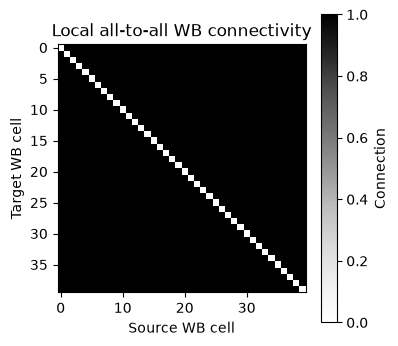

In [2]:
n_wb_per_area = 40
W_local = np.ones((n_wb_per_area, n_wb_per_area), dtype=np.int8)
np.fill_diagonal(W_local, 0)

local_targets, local_sources = np.where(W_local > 0)
print("WB cells in each area:", n_wb_per_area)
print("Local matrix shape:", W_local.shape)
print("Incoming WB connections per cell:", int(W_local.sum(axis=1)[0]))
print("Total directed WB-to-WB links per area:", len(local_sources))

plt.figure(figsize=(4, 4))
plt.imshow(W_local, cmap="Greys", interpolation="nearest")
plt.xlabel("Source WB cell")
plt.ylabel("Target WB cell")
plt.title("Local all-to-all WB connectivity")
plt.colorbar(label="Connection")
plt.show()

## Step 3: Prepare the inter-area FLN weights

We apply the original power transform and incoming-row normalization on the full 40-area anatomical matrix first, then select the 12-area subnetwork. This preserves the original weights; links from omitted areas are not reassigned to the selected areas, so some retained areas will receive less total input than in the full model.


In [3]:
fln_a = float(template_kwargs["fln_a"])
fln_b = float(template_kwargs["fln_b"])
scaled_fln_full = fln_a * np.clip(all_raw_fln, 0.0, None) ** fln_b
incoming_totals_full = np.nansum(scaled_fln_full, axis=1, keepdims=True)
fln_weights_full = np.divide(
    scaled_fln_full,
    incoming_totals_full,
    out=np.zeros_like(scaled_fln_full),
    where=incoming_totals_full > 0,
)
fln_weights_full = np.nan_to_num(fln_weights_full)
fln_weights = fln_weights_full[np.ix_(simulation_area_indices, simulation_area_indices)]

print("FLN direction: source area j -> target area i")
print("Directed links in reduced network:", int(np.count_nonzero(fln_weights)))
print("Retained incoming weight sum range:",
      float(fln_weights.sum(axis=1).min()),
      "to", float(fln_weights.sum(axis=1).max()))
print("Self-links in reduced FLN:", int(np.count_nonzero(np.diag(fln_weights))))

FLN direction: source area j -> target area i
Directed links in reduced network: 999
Retained incoming weight sum range: 0.9999999999999998 to 1.0000000000000002
Self-links in reduced FLN: 0


## Step 4: Set the network and candidate parameters

`network_mode` in Step 1 is currently `"full"`, so each run simulates all 40 anatomical areas (160 RTM and 1,600 WB cells). The selected candidate is pulse 110, FLN conductance 0.10 mS/cm², and `tau_long = 4 ms`. To speed up future pilots, Step 1 can be switched to `"reduced"` (12 areas). The reduced grid and seed checks are skipped in full mode; full-network seed validation runs below the main plot.


In [4]:
n_rtm_per_area = 4
n_rtm_total = n_areas * n_rtm_per_area
n_wb_per_area = 40
n_wb_total = n_areas * n_wb_per_area
area_for_rtm = np.repeat(np.arange(n_areas), n_rtm_per_area)
area_for_wb = np.repeat(np.arange(n_areas), n_wb_per_area)

run_duration = 600 * ms  # 100 ms after the 500 ms stimulus ends
dt = 0.01 * ms
base_current = 0.0                 # microampere/cm^2
pulse_current = 110               # microampere/cm^2 (full-network candidate)
pulse_on = 50 * ms
pulse_off = 500 * ms
stimulated_area = "V4"

# Provisional heterogeneity: small seeded variation in RTM sodium conductance.
rtm_gNa_sd_fraction = 0.01
rtm_random_seed = 1

# Provisional synaptic conductance scales
rtm_to_wb_total_conductance = 0.2 * msiemens / cm**2
wb_to_rtm_total_conductance = 0.6 * msiemens / cm**2
wb_to_wb_total_conductance = 0.2 * msiemens / cm**2
interarea_total_conductance = 0.10 * msiemens / cm**2  # full-network candidate from sweep
tau_exc = 2 * ms
tau_inh = 10 * ms
tau_long = 4 * ms  # fixed during FLN and seed validation

# Provisional GNW broadcast: a small global excitatory conductance pulse after online ignition.
gnw_broadcast_conductance = 0.005 * msiemens / cm**2
tau_gnw_broadcast = 50 * ms
gnw_broadcast_detector_dt = 1 * ms

print("Simulation duration:", run_duration / ms, "ms")
print("Integration step:", dt / ms, "ms")
print("Cells:", n_rtm_total, "RTM and", n_wb_total, "WB")
print("Per area:", n_rtm_per_area, "RTM and", n_wb_per_area, "WB")
print("Stimulus:", stimulated_area, "from", pulse_on / ms, "to", pulse_off / ms, "ms")
print("FLN conductance:", interarea_total_conductance / (msiemens / cm**2), "mS/cm^2")
print("FLN conductance decay:", tau_long / ms, "ms")
print("RTM sodium-conductance SD:", rtm_gNa_sd_fraction * 100, "% of mean gNa")


Simulation duration: 600.0 ms
Integration step: 0.01 ms
Cells: 160 RTM and 1600 WB
Per area: 4 RTM and 40 WB
Stimulus: V4 from 50.0 to 500.0 ms
FLN conductance: 0.1 mS/cm^2
FLN conductance decay: 4.0 ms
RTM sodium-conductance SD: 1.0 % of mean gNa


## Step 5: Define the RTM and WB cell equations

RTM cells receive the external pulse, local WB inhibition, and long-range excitatory input from other RTM cells. WB cells receive local RTM excitation and inhibition from the other WB cells in their area.

In [5]:
rtm_equations = "\n".join([
    "dv/dt = (I_app + I_inh + I_long + I_broadcast - gNa_cell*m_inf**3*h*(v-vNa) - gK*n**4*(v-vK) - gL*(v-vL))/C_m : volt",
    "dh/dt = alpha_h*(1-h)-beta_h*h : 1",
    "dn/dt = alpha_n*(1-n)-beta_n*n : 1",
    "alpha_m = (1.28/ms)/exprel(-(v/mV+54)/4) : Hz",
    "beta_m = (1.4/ms)/exprel((v/mV+27)/5) : Hz",
    "alpha_h = (0.128/ms)*exp(-(v/mV+50)/18) : Hz",
    "beta_h = (4/ms)/(1+exp(-(v/mV+27)/5)) : Hz",
    "alpha_n = (0.16/ms)/exprel(-(v/mV+52)/5) : Hz",
    "beta_n = (0.5/ms)*exp(-(v/mV+57)/40) : Hz",
    "m_inf = alpha_m/(alpha_m+beta_m+1e-12*Hz) : 1",
    "I_app = input_current(t, area_index) : amp/meter**2",
    "gNa_cell : siemens/meter**2 (constant)",
    "I_inh = g_inh*(E_inh-v) : amp/meter**2",
    "dg_inh/dt = -g_inh/tau_inh : siemens/meter**2",
    "I_long = g_long*(E_exc-v) : amp/meter**2",
    "dg_long/dt = -g_long/tau_long : siemens/meter**2",
    "I_broadcast = g_broadcast*(E_exc-v) : amp/meter**2",
    "dg_broadcast/dt = -g_broadcast/tau_broadcast : siemens/meter**2",
    "area_index : integer (constant)",
])

wb_equations = "\n".join([
    "dv/dt = (I_app + I_exc + I_inh - gNa*m_inf**3*h*(v-vNa) - gK*n**4*(v-vK) - gL*(v-vL))/C_m : volt",
    "dh/dt = alpha_h*(1-h)-beta_h*h : 1",
    "dn/dt = alpha_n*(1-n)-beta_n*n : 1",
    "alpha_m = (1/ms)/exprel(-(v/mV+35)/10) : Hz",
    "beta_m = 4*exp(-(v/mV+60)/18)/ms : Hz",
    "alpha_h = 0.07*exp(-(v/mV+58)/20)/ms : Hz",
    "beta_h = 1/(1+exp(-(v/mV+28)/10))/ms : Hz",
    "alpha_n = (0.1/ms)/exprel(-(v/mV+34)/10) : Hz",
    "beta_n = 0.125*exp(-(v/mV+44)/80)/ms : Hz",
    "m_inf = alpha_m/(alpha_m+beta_m+1e-12*Hz) : 1",
    "I_app = 0*amp/meter**2 : amp/meter**2",
    "I_exc = g_exc*(E_exc-v) : amp/meter**2",
    "dg_exc/dt = -g_exc/tau_exc : siemens/meter**2",
    "I_inh = g_inh*(E_inh-v) : amp/meter**2",
    "dg_inh/dt = -g_inh/tau_inh : siemens/meter**2",
    "area_index : integer (constant)",
])

print("RTM and WB equations are defined.")

RTM and WB equations are defined.


## Step 6: Build and run one condition

Each of the 12 selected areas contains four RTM cells and 40 WB cells. Each RTM excites the WB cells in its own area; local WB cells inhibit all four RTMs and connect to other local WB cells. In the connected condition, the selected areas exchange RTM input through the corresponding submatrix of the full-network FLN weights.


In [6]:
def run_condition(
    use_interarea_links,
    pulse_current_value=None,
    interarea_conductance_value=None,
    tau_long_value=None,
    rtm_seed_value=None,
    enable_gnw_broadcast=False,
    broadcast_conductance_value=None,
    tau_gnw_broadcast_value=None,
    run_duration_value=None,
):
    pulse_current_used = pulse_current if pulse_current_value is None else float(pulse_current_value)
    interarea_conductance_used = (
        interarea_total_conductance
        if interarea_conductance_value is None
        else interarea_conductance_value
    )
    tau_long_used = tau_long if tau_long_value is None else tau_long_value
    rtm_seed_used = rtm_random_seed if rtm_seed_value is None else int(rtm_seed_value)
    broadcast_conductance_used = (
        gnw_broadcast_conductance
        if broadcast_conductance_value is None
        else broadcast_conductance_value
    )
    tau_broadcast_used = (
        tau_gnw_broadcast
        if tau_gnw_broadcast_value is None
        else tau_gnw_broadcast_value
    )
    duration_used = run_duration if run_duration_value is None else run_duration_value
    simulation_clock = Clock(dt=dt)
    n_rtm_total = n_areas * n_rtm_per_area
    n_wb_total = n_areas * n_wb_per_area
    area_for_rtm = np.repeat(np.arange(n_areas), n_rtm_per_area)
    area_for_wb = np.repeat(np.arange(n_areas), n_wb_per_area)
    n_steps = int(np.ceil(float(duration_used / dt))) + 1
    time_values_ms = np.arange(n_steps) * float(dt / ms)
    current_values = np.full((n_steps, n_areas), base_current, dtype=float)
    pulse_mask = (
        (time_values_ms >= float(pulse_on / ms))
        & (time_values_ms <= float(pulse_off / ms))
    )
    current_values[pulse_mask, area_labels.index(stimulated_area)] = pulse_current_used
    input_current = TimedArray(current_values * uA / cm**2, dt=dt)

    shared_namespace = {
        "C_m": 1.0 * uF / cm**2,
        "gNa": 100.0 * msiemens / cm**2,
        "gK": 80.0 * msiemens / cm**2,
        "gL": 0.1 * msiemens / cm**2,
        "vNa": 50.0 * mV,
        "vK": -100.0 * mV,
        "vL": -67.0 * mV,
        "E_exc": 0.0 * mV,
        "E_inh": -75.0 * mV,
        "tau_inh": tau_inh,
    }

    rtm_cells = NeuronGroup(
        n_rtm_total,
        rtm_equations,
        threshold="v > 0*mV",
        reset="v = -65*mV",
        method="rk4",
        clock=simulation_clock,
        namespace={
            **shared_namespace,
            "input_current": input_current,
            "tau_long": tau_long_used,
            "tau_broadcast": tau_broadcast_used,
        },
    )
    rtm_cells.v = -64.9997224337346 * mV
    rtm_cells.h = 0.596111046346827
    rtm_cells.n = 0.317681167579781
    rtm_cells.area_index = area_for_rtm
    rng = np.random.default_rng(rtm_seed_used)
    rtm_gNa_values = rng.normal(
        1.0,
        rtm_gNa_sd_fraction,
        size=n_rtm_total,
    )
    rtm_cells.gNa_cell = 100.0 * msiemens / cm**2 * rtm_gNa_values
    rtm_cells.g_inh = 0 * siemens / cm**2
    rtm_cells.g_long = 0 * siemens / cm**2
    rtm_cells.g_broadcast = 0 * siemens / cm**2

    wb_cells = NeuronGroup(
        n_wb_total,
        wb_equations,
        threshold="v > 0*mV",
        reset="v = -65*mV",
        method="exponential_euler",
        clock=simulation_clock,
        namespace={
            **shared_namespace,
            "gNa": 35.0 * msiemens / cm**2,
            "gK": 9.0 * msiemens / cm**2,
            "vNa": 55.0 * mV,
            "vK": -90.0 * mV,
            "vL": -65.0 * mV,
            "tau_exc": tau_exc,
        },
    )
    wb_cells.v = -65.0 * mV
    wb_cells.h = 0.6
    wb_cells.n = 0.3
    wb_cells.area_index = area_for_wb
    wb_cells.g_exc = 0 * siemens / cm**2
    wb_cells.g_inh = 0 * siemens / cm**2

    # Every RTM excites the 40 WB cells in its own area.
    # Divide by the number of RTMs to keep the synchronous population's total
    # RTM-to-WB conductance comparable to the one-RTM prototype.
    rtm_to_wb_i = np.concatenate([
        np.repeat(area_idx * n_rtm_per_area + np.arange(n_rtm_per_area), n_wb_per_area)
        for area_idx in range(n_areas)
    ])
    rtm_to_wb_j = np.concatenate([
        np.tile(np.arange(area_idx * n_wb_per_area,
                          (area_idx + 1) * n_wb_per_area), n_rtm_per_area)
        for area_idx in range(n_areas)
    ])
    rtm_to_wb = Synapses(
        rtm_cells, wb_cells,
        clock=simulation_clock,
        on_pre="g_exc_post += g_jump",
        namespace={"g_jump": rtm_to_wb_total_conductance / n_rtm_per_area},
    )
    rtm_to_wb.connect(i=rtm_to_wb_i, j=rtm_to_wb_j)

    # Each WB cell in an area inhibits all four RTM cells in that area.
    wb_to_rtm_i = np.concatenate([
        np.repeat(area_idx * n_wb_per_area + np.arange(n_wb_per_area), n_rtm_per_area)
        for area_idx in range(n_areas)
    ])
    wb_to_rtm_j = np.concatenate([
        np.tile(area_idx * n_rtm_per_area + np.arange(n_rtm_per_area), n_wb_per_area)
        for area_idx in range(n_areas)
    ])
    wb_to_rtm = Synapses(
        wb_cells, rtm_cells,
        clock=simulation_clock,
        on_pre="g_inh_post += g_jump",
        namespace={"g_jump": wb_to_rtm_total_conductance / n_wb_per_area},
    )
    wb_to_rtm.connect(i=wb_to_rtm_i, j=wb_to_rtm_j)

    # Replicate the 40x40 local W matrix independently in every area.
    local_sources_all = np.concatenate([
        area_idx * n_wb_per_area + local_sources
        for area_idx in range(n_areas)
    ])
    local_targets_all = np.concatenate([
        area_idx * n_wb_per_area + local_targets
        for area_idx in range(n_areas)
    ])
    wb_to_wb = Synapses(
        wb_cells, wb_cells,
        clock=simulation_clock,
        on_pre="g_inh_post += g_jump",
        namespace={
            "g_jump": wb_to_wb_total_conductance / (n_wb_per_area - 1)
        },
    )
    wb_to_wb.connect(i=local_sources_all, j=local_targets_all)

    objects = [rtm_cells, wb_cells, rtm_to_wb, wb_to_rtm, wb_to_wb]
    if use_interarea_links:
        target_areas, source_areas = np.nonzero(fln_weights)
        rtm_to_rtm = Synapses(
            rtm_cells, rtm_cells,
            clock=simulation_clock,
            model="fln_weight : 1",
            on_pre="g_long_post += g_jump * fln_weight",
            namespace={
                "g_jump": interarea_conductance_used / n_rtm_per_area,
            },
        )
        # Expand each area-to-area FLN edge to all source/target RTM pairs.
        source_cells = np.concatenate([
            np.repeat(source_area * n_rtm_per_area + np.arange(n_rtm_per_area), n_rtm_per_area)
            for source_area in source_areas
        ])
        target_cells = np.concatenate([
            np.tile(target_area * n_rtm_per_area + np.arange(n_rtm_per_area), n_rtm_per_area)
            for target_area in target_areas
        ])
        edge_weights = np.repeat(
            fln_weights[target_areas, source_areas],
            n_rtm_per_area * n_rtm_per_area,
        )
        rtm_to_rtm.connect(i=source_cells, j=target_cells)
        rtm_to_rtm.fln_weight = edge_weights
        objects.append(rtm_to_rtm)

    rtm_voltage_monitor = StateMonitor(rtm_cells, "v", record=True, clock=simulation_clock)
    v4_wb_start = area_labels.index("V4") * n_wb_per_area
    v4_wb_indices = np.arange(v4_wb_start, v4_wb_start + n_wb_per_area)
    v4_wb_voltage_monitor = StateMonitor(
        wb_cells, "v", record=v4_wb_indices, clock=simulation_clock
    )
    rtm_spikes = SpikeMonitor(rtm_cells)
    wb_spikes = SpikeMonitor(wb_cells)
    objects.extend([
        rtm_voltage_monitor, v4_wb_voltage_monitor, rtm_spikes, wb_spikes
    ])

    online_ignition_onset_ms = np.nan
    broadcast_trigger_time_ms = np.nan
    broadcast_triggered = False
    if enable_gnw_broadcast:
        detector_dt_ms = float(gnw_broadcast_detector_dt / ms)
        sustained_above_ms = 0.0
        workspace_cell_count = len(workspace_indices) * n_rtm_per_area

        def update_online_ignition(t):
            nonlocal online_ignition_onset_ms
            nonlocal broadcast_trigger_time_ms
            nonlocal broadcast_triggered
            nonlocal sustained_above_ms

            now_ms = float(t / ms)
            if now_ms < float(pulse_on / ms):
                sustained_above_ms = 0.0
                return

            spike_times_ms = np.asarray(rtm_spikes.t / ms, dtype=float)
            spike_cells = np.asarray(rtm_spikes.i, dtype=int)
            spike_areas = area_for_rtm[spike_cells]
            recent = (
                (spike_times_ms > now_ms - rate_window_ms)
                & (spike_times_ms <= now_ms)
                & np.isin(spike_areas, workspace_indices)
            )
            recent_count = int(np.count_nonzero(recent))
            workspace_mean_hz = (
                recent_count * 1000.0 / (rate_window_ms * workspace_cell_count)
            )
            if workspace_mean_hz >= ignition_threshold_hz:
                sustained_above_ms += detector_dt_ms
            else:
                sustained_above_ms = 0.0

            if (
                not broadcast_triggered
                and sustained_above_ms >= ignition_min_duration_ms
            ):
                broadcast_triggered = True
                broadcast_trigger_time_ms = now_ms
                online_ignition_onset_ms = now_ms - ignition_min_duration_ms + detector_dt_ms
                rtm_cells.g_broadcast[:] += broadcast_conductance_used

        ignition_detector = NetworkOperation(
            update_online_ignition,
            clock=Clock(dt=gnw_broadcast_detector_dt),
            when="end",
        )
        objects.append(ignition_detector)

    network = Network(*objects)
    network.run(duration_used, namespace={})

    rtm_spike_cell = np.asarray(rtm_spikes.i, dtype=int)
    rtm_spike_area = area_for_rtm[rtm_spike_cell]
    rtm_spikes_per_area = np.bincount(
        rtm_spike_area, minlength=n_areas
    )
    wb_spikes_per_area = np.bincount(
        np.asarray(wb_spikes.i, dtype=int) // n_wb_per_area,
        minlength=n_areas,
    )
    return {
        "time_ms": np.asarray(rtm_voltage_monitor.t / ms),
        "rtm_voltage_by_cell_mv": np.asarray(rtm_voltage_monitor.v / mV).T,
        "rtm_voltage_mv": np.asarray(rtm_voltage_monitor.v / mV).T.reshape(
            -1, n_areas, n_rtm_per_area
        ).mean(axis=2),
        "v4_wb_voltage_mv": np.asarray(v4_wb_voltage_monitor.v / mV).T,
        "rtm_spike_times_ms": np.asarray(rtm_spikes.t / ms),
        "rtm_spike_area": rtm_spike_area,
        "rtm_spike_cell": rtm_spike_cell,
        "wb_spike_times_ms": np.asarray(wb_spikes.t / ms),
        "wb_spike_cell": np.asarray(wb_spikes.i, dtype=int),
        "rtm_spikes_per_area": rtm_spikes_per_area,
        "wb_spikes_per_area": wb_spikes_per_area,
        "online_ignition_onset_ms": float(online_ignition_onset_ms),
        "broadcast_trigger_time_ms": float(broadcast_trigger_time_ms),
        "gnw_broadcast_triggered": bool(broadcast_triggered),
    }

## Step 7: Compare FLN disconnected and connected runs

The local RTM–WB circuits are identical in both runs. Only the inter-area RTM-to-RTM FLN links change.

In [7]:
from tqdm.auto import tqdm

baseline_results = {}
for links_enabled in tqdm([False, True], desc="Baseline FLN comparison", unit="run"):
    baseline_results[links_enabled] = run_condition(
        use_interarea_links=links_enabled
    )
uncoupled = baseline_results[False]
connected = baseline_results[True]

del baseline_results

v4_index = area_labels.index("V4")
print("RTM cells:", n_rtm_total, f"({n_rtm_per_area} per area)")
print("WB cells:", n_areas * n_wb_per_area)
print("V4 RTM spikes, FLN off:", uncoupled["rtm_spikes_per_area"][v4_index])
print("V4 RTM spikes, FLN on:", connected["rtm_spikes_per_area"][v4_index])
print("Total WB spikes, FLN off:", int(uncoupled["wb_spikes_per_area"].sum()))
print("Total WB spikes, FLN on:", int(connected["wb_spikes_per_area"].sum()))

Baseline FLN comparison:   0%|          | 0/2 [00:00<?, ?run/s]

RTM cells: 160 (4 per area)
WB cells: 1600
V4 RTM spikes, FLN off: 4319
V4 RTM spikes, FLN on: 4484
Total WB spikes, FLN off: 10480
Total WB spikes, FLN on: 47920


## Step 8: Plot V4 and its strongest FLN targets

FLN[target, V4] is read from the V4 column. The target traces show whether enabling inter-area links changes RTM voltage in the areas most strongly connected from V4.

V4: maximum absolute voltage difference = 54.5469 mV
V2: maximum absolute voltage difference = 42.1639 mV
MT: maximum absolute voltage difference = 51.5665 mV
V1: maximum absolute voltage difference = 40.6229 mV
TEO: maximum absolute voltage difference = 45.4183 mV
DP: maximum absolute voltage difference = 39.8991 mV


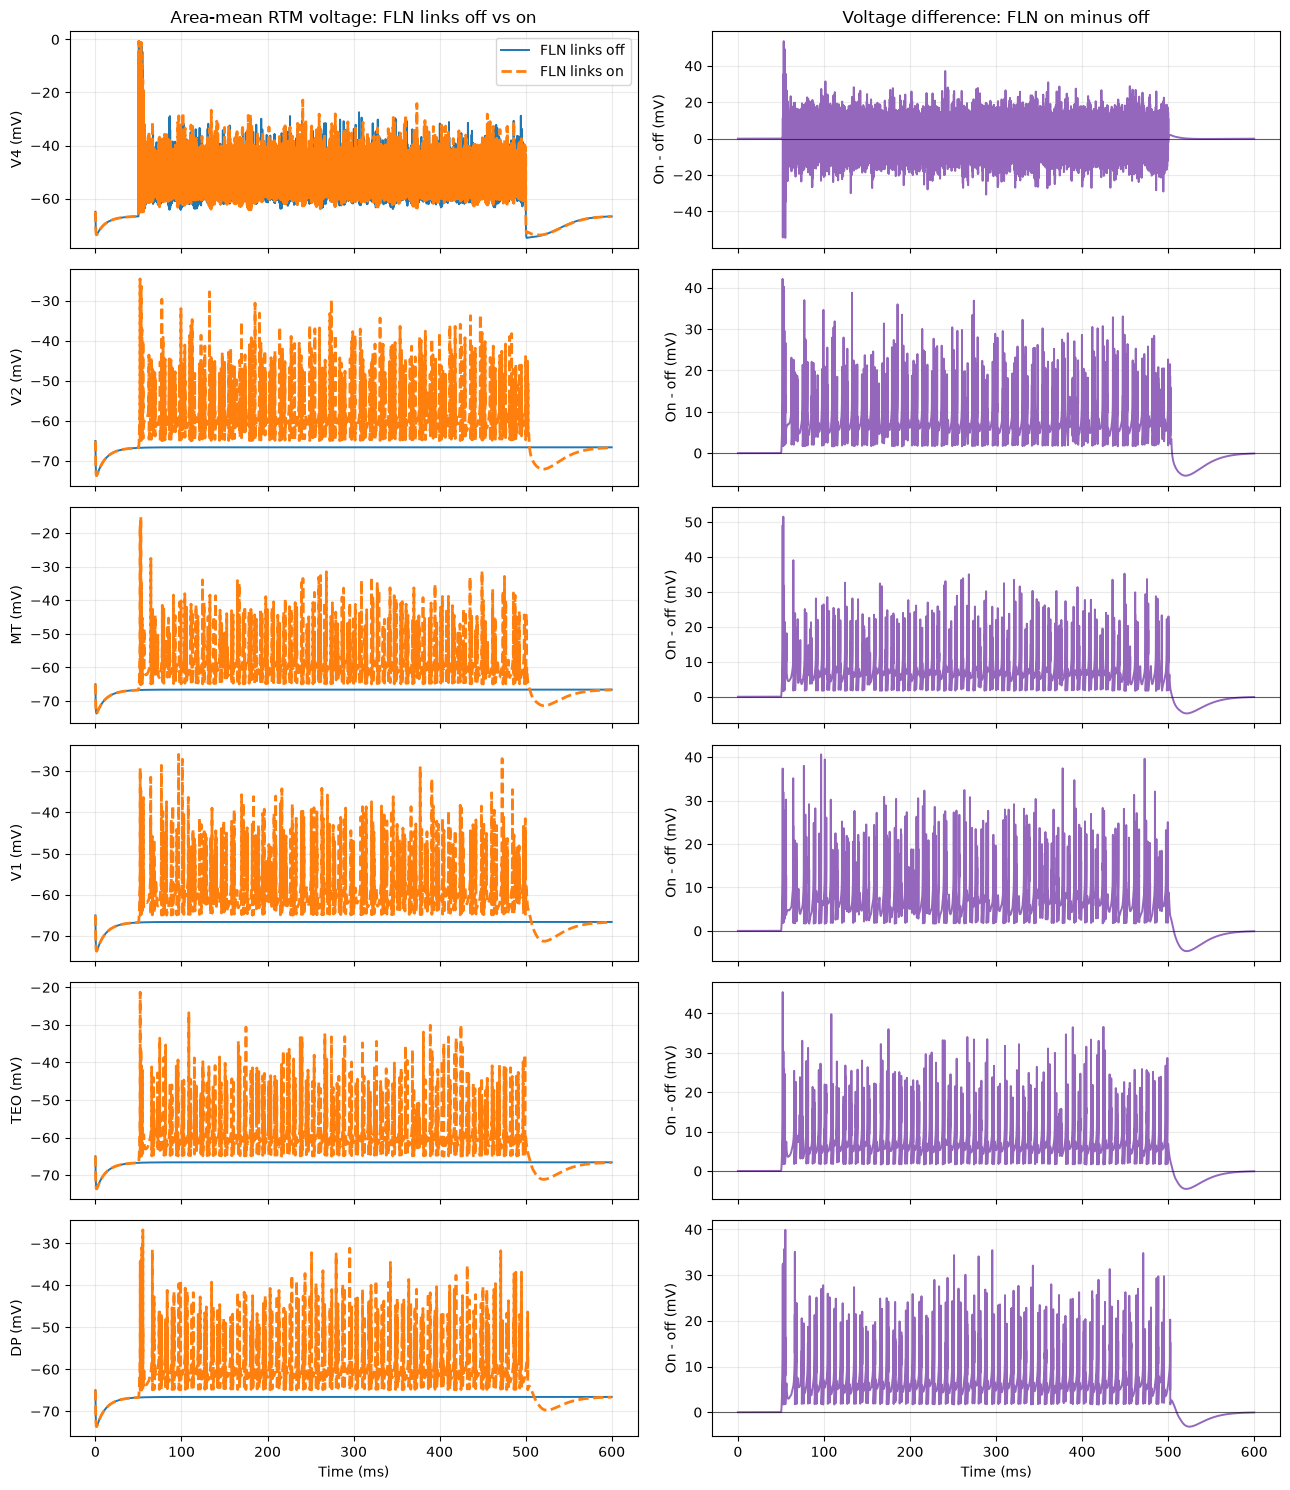

Strongest V4 outgoing targets:
V4 -> V2: FLN weight 0.2139
V4 -> MT: FLN weight 0.1908
V4 -> V1: FLN weight 0.1800
V4 -> TEO: FLN weight 0.1796
V4 -> DP: FLN weight 0.1645


In [8]:
v4_index = area_labels.index("V4")
v4_outgoing = fln_weights[:, v4_index].copy()
v4_outgoing[v4_index] = 0.0
target_order = np.argsort(v4_outgoing)[::-1]
target_indices = [i for i in target_order if v4_outgoing[i] > 0][:5]
areas_to_plot = [v4_index] + target_indices

fig, axes = plt.subplots(
    len(areas_to_plot), 2,
    figsize=(13, 2.5 * len(areas_to_plot)),
    sharex=True,
)
axes = np.atleast_2d(axes)
for row, area_idx in enumerate(areas_to_plot):
    ax_voltage = axes[row, 0]
    ax_difference = axes[row, 1]
    uncoupled_v = uncoupled["rtm_voltage_mv"][:, area_idx]
    connected_v = connected["rtm_voltage_mv"][:, area_idx]
    ax_voltage.plot(
        uncoupled["time_ms"], uncoupled_v,
        color="tab:blue", linestyle="-", linewidth=1.4,
        label="FLN links off",
    )
    ax_voltage.plot(
        connected["time_ms"], connected_v,
        color="tab:orange", linestyle="--", linewidth=2.0,
        label="FLN links on",
    )
    ax_voltage.set_ylabel(f"{area_labels[area_idx]} (mV)")
    ax_voltage.grid(alpha=0.25)

    difference_mv = connected_v - uncoupled_v
    ax_difference.plot(
        connected["time_ms"], difference_mv,
        color="tab:purple", linewidth=1.4,
    )
    ax_difference.axhline(0, color="black", linewidth=0.8, alpha=0.6)
    ax_difference.set_ylabel("On - off (mV)")
    ax_difference.grid(alpha=0.25)
    print(
        f"{area_labels[area_idx]}: maximum absolute voltage difference = "
        f"{np.max(np.abs(difference_mv)):.6g} mV"
    )

axes[0, 0].legend()
axes[0, 0].set_title("Area-mean RTM voltage: FLN links off vs on")
axes[0, 1].set_title("Voltage difference: FLN on minus off")
axes[-1, 0].set_xlabel("Time (ms)")
axes[-1, 1].set_xlabel("Time (ms)")
plt.tight_layout()
plt.show()

print("Strongest V4 outgoing targets:")
for area_idx in target_indices:
    print(f"V4 -> {area_labels[area_idx]}: FLN weight {v4_outgoing[area_idx]:.4f}")


## Step 9: Inspect the local WB network in V4

This raster shows WB spikes from V4's 40-cell inhibitory network. The voltage plot records all 40 WB cells in V4, so you can see whether the local population responds to V4 RTM activity.

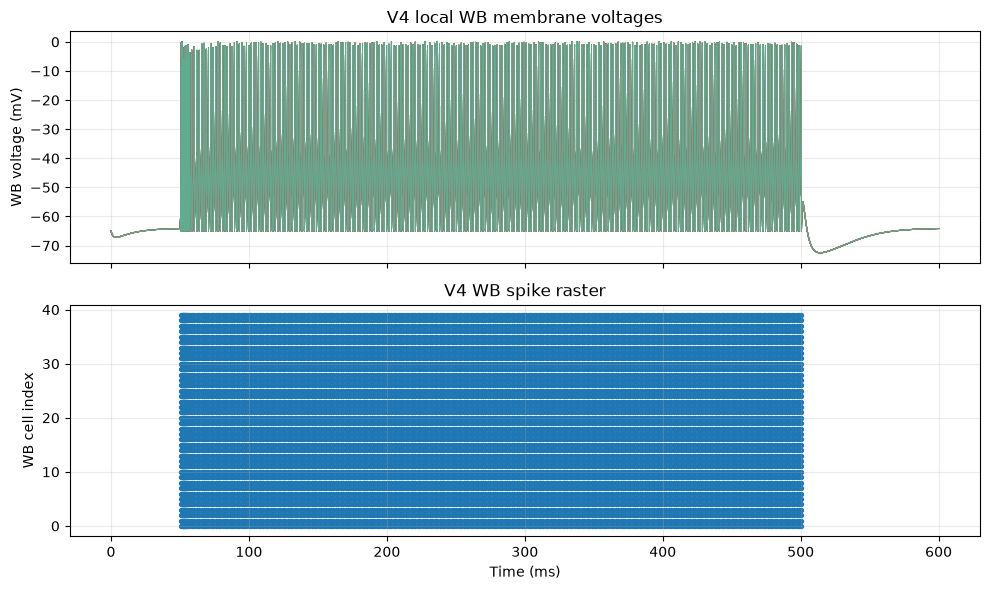

In [9]:
v4_wb_start = v4_index * n_wb_per_area
v4_wb_end = v4_wb_start + n_wb_per_area
v4_wb_mask = (
    (connected["wb_spike_cell"] >= v4_wb_start)
    & (connected["wb_spike_cell"] < v4_wb_end)
)
v4_wb_spike_cells = connected["wb_spike_cell"][v4_wb_mask] - v4_wb_start
v4_wb_spike_times = connected["wb_spike_times_ms"][v4_wb_mask]

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for cell_idx in range(n_wb_per_area):
    axes[0].plot(
        connected["time_ms"],
        connected["v4_wb_voltage_mv"][:, cell_idx],
        alpha=0.5,
        linewidth=0.7,
    )
axes[0].set_ylabel("WB voltage (mV)")
axes[0].set_title("V4 local WB membrane voltages")
axes[1].scatter(v4_wb_spike_times, v4_wb_spike_cells, s=8)
axes[1].set_ylabel("WB cell index")
axes[1].set_xlabel("Time (ms)")
axes[1].set_title("V4 WB spike raster")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## How to interpret the reduced tuning network

- This tuning subnetwork contains V4, five strongest direct V4 FLN targets, and the six selected workspace areas: 12 areas total, 48 RTM cells, and 480 WB cells.
- The anatomical FLN weights are normalized across all 40 areas before selecting the subnetwork. Projections from omitted areas are absent; their weight is not redistributed.
- Each selected area retains four RTM cells and 40 WB cells, with the same local connectivity and within-area conductance scaling as the full network.
- The selected subnetwork is useful for faster parameter screening, but activity can differ from the full network because omitted areas cannot provide input.
- After choosing a stable parameter range, restore the full 40-area network and validate the result before drawing conclusions.
- The current units, conductances, and small seeded RTM sodium-conductance differences are provisional assumptions.


## Step 10: Define the GNW workspace and ignition rule

The workspace uses the previously selected frontoparietal areas F1, F2, F3, F4, 7a, and 7b. The project GNW metric treats ignition as a workspace mean RTM rate of at least 20 Hz sustained for 50 ms, starting after stimulus onset. We apply this existing readout to the RTM spike trains from the spiking network.

In [10]:
workspace_areas = ["F1", "F2", "F3", "F4", "7a", "7b"]
workspace_indices = resolve_area_indices(area_labels, workspace_areas)
ignition_threshold_hz = 20.0
ignition_min_duration_ms = 50.0
rate_window_ms = 50.0
stimulus_onset_ms = float(pulse_on / ms)

print("GNW workspace areas:", workspace_areas)
print("Workspace area indices:", workspace_indices.tolist())
print("Ignition criterion:",
      f"workspace mean >= {ignition_threshold_hz:g} Hz for "
      f"{ignition_min_duration_ms:g} ms")
print("Rate-estimation window:", rate_window_ms, "ms")

GNW workspace areas: ['F1', 'F2', 'F3', 'F4', '7a', '7b']
Workspace area indices: [14, 34, 18, 10, 16, 33]
Ignition criterion: workspace mean >= 20 Hz for 50 ms
Rate-estimation window: 50.0 ms


## Step 11: Convert RTM spikes to area-rate traces

For each brain area, we count spikes from its four RTM cells in a trailing 50 ms window, then divide by four. This gives the mean per-cell rate for that area. Four cells improve rate resolution compared with a single RTM, although the estimate is still based on a small population.


In [11]:
def rtm_spikes_to_rate_trace(result, area_count, window_ms, cells_per_area):
    time_ms = np.asarray(result["time_ms"], dtype=float)
    dt_ms = float(np.median(np.diff(time_ms)))
    spike_times = np.asarray(result["rtm_spike_times_ms"], dtype=float)
    spike_areas = np.asarray(result["rtm_spike_area"], dtype=int)

    spike_counts = np.zeros((len(time_ms), area_count), dtype=float)
    sample_indices = np.rint(spike_times / dt_ms).astype(int)
    valid = (
        (sample_indices >= 0) & (sample_indices < len(time_ms))
        & (spike_areas >= 0) & (spike_areas < area_count)
    )
    np.add.at(spike_counts, (sample_indices[valid], spike_areas[valid]), 1.0)

    window_samples = max(1, int(round(window_ms / dt_ms)))
    cumulative = np.vstack([
        np.zeros((1, area_count)), np.cumsum(spike_counts, axis=0)
    ])
    end_indices = np.arange(1, len(time_ms) + 1)
    start_indices = np.maximum(0, end_indices - window_samples)
    counts_in_window = cumulative[end_indices] - cumulative[start_indices]
    rates_hz = counts_in_window * (1000.0 / window_ms) / cells_per_area
    return rates_hz

uncoupled_rtm_rates_hz = rtm_spikes_to_rate_trace(
    uncoupled, n_areas, rate_window_ms, n_rtm_per_area
)
connected_rtm_rates_hz = rtm_spikes_to_rate_trace(
    connected, n_areas, rate_window_ms, n_rtm_per_area
)
time_ms = connected["time_ms"]
print("Rate array shape (time points, areas):", connected_rtm_rates_hz.shape)
print("Maximum RTM rate, FLN off:", float(uncoupled_rtm_rates_hz.max()), "Hz")
print("Maximum RTM rate, FLN on:", float(connected_rtm_rates_hz.max()), "Hz")

Rate array shape (time points, areas): (60000, 40)
Maximum RTM rate, FLN off: 2425.0 Hz
Maximum RTM rate, FLN on: 2535.0 Hz


## Step 12: Measure workspace ignition in both conditions

We evaluate the same workspace and threshold in the FLN-off control and FLN-on run. A transient target-area spike is not automatically GNW ignition: the workspace mean must remain above threshold for the required duration.

In [12]:
ignition_off = compute_ignition_metrics(
    uncoupled_rtm_rates_hz,
    time_ms,
    workspace_indices,
    threshold_hz=ignition_threshold_hz,
    min_duration_ms=ignition_min_duration_ms,
    onset_ms=stimulus_onset_ms,
)
ignition_on = compute_ignition_metrics(
    connected_rtm_rates_hz,
    time_ms,
    workspace_indices,
    threshold_hz=ignition_threshold_hz,
    min_duration_ms=ignition_min_duration_ms,
    onset_ms=stimulus_onset_ms,
)

for label, metrics in (("FLN off", ignition_off), ("FLN on", ignition_on)):
    print(f"{label}: ignited={metrics['ignited']}")
    print(f"  first qualifying time: {metrics['ignition_time_ms']:.2f} ms")
    print(f"  latency from stimulus onset: {metrics['latency_ms']:.2f} ms")

FLN off: ignited=False
  first qualifying time: nan ms
  latency from stimulus onset: nan ms
FLN on: ignited=True
  first qualifying time: 60.14 ms
  latency from stimulus onset: 10.14 ms


## Step 13: Plot workspace activity and compare conditions

The upper panel shows the mean rate across workspace areas. The lower panel shows each workspace area's RTM rate in the FLN-on run, helping identify which areas contribute to the mean.

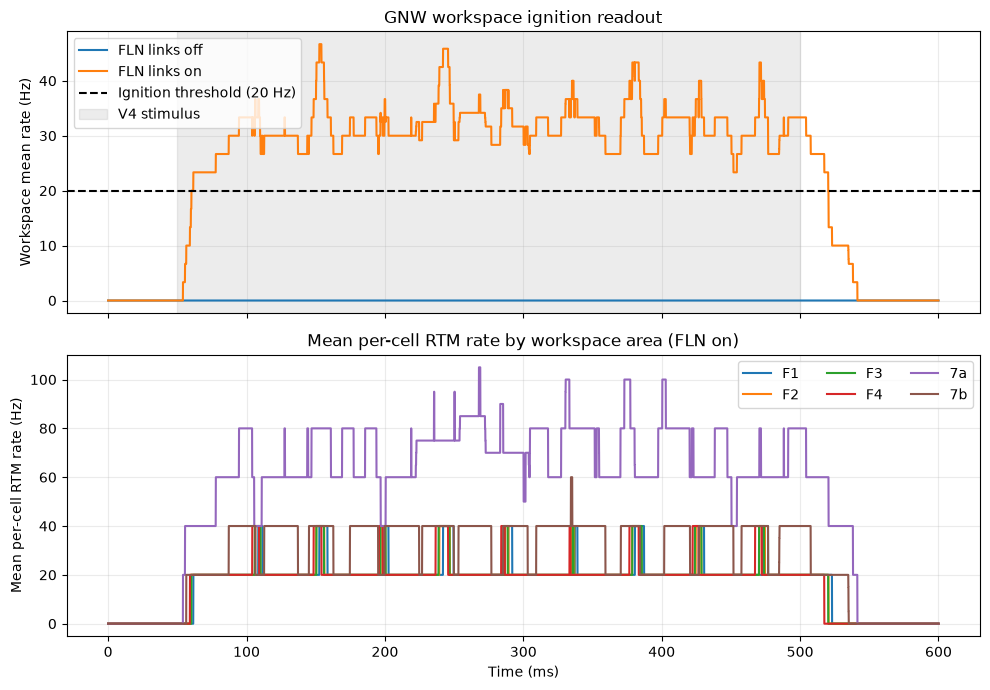

In [13]:
workspace_rate_off = ignition_off["workspace_rate_hz"]
workspace_rate_on = ignition_on["workspace_rate_hz"]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(time_ms, workspace_rate_off, label="FLN links off", color="tab:blue")
axes[0].plot(time_ms, workspace_rate_on, label="FLN links on", color="tab:orange")
axes[0].axhline(
    ignition_threshold_hz, color="black", linestyle="--",
    label=f"Ignition threshold ({ignition_threshold_hz:g} Hz)",
)
axes[0].axvspan(
    stimulus_onset_ms, float(pulse_off / ms), color="gray", alpha=0.15,
    label="V4 stimulus",
)
axes[0].set_ylabel("Workspace mean rate (Hz)")
axes[0].set_title("GNW workspace ignition readout")
axes[0].legend()
axes[0].grid(alpha=0.25)

for area_idx in workspace_indices:
    axes[1].plot(
        time_ms,
        connected_rtm_rates_hz[:, area_idx],
        label=area_labels[area_idx],
    )
axes[1].set_ylabel("Mean per-cell RTM rate (Hz)")
axes[1].set_xlabel("Time (ms)")
axes[1].set_title("Mean per-cell RTM rate by workspace area (FLN on)")
axes[1].legend(ncol=3)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Full-network seed validation

This validates the selected full-network candidate (`pulse_current = 110`, FLN conductance = 0.10 mS/cm², `tau_long = 4 ms`) across three paired RTM heterogeneity seeds. Seed 1 reuses the baseline runs above; seeds 2 and 3 add four full-network simulations. The FLN-off and FLN-on runs use the same seed in each pair.


In [14]:
import gc
import pandas as pd
from tqdm.auto import tqdm

if network_mode == "full":
    full_validation_seeds = [1, 2, 3]
    full_seed_rows = []

    def _summarize_full_seed_run(result):
        rates = rtm_spikes_to_rate_trace(
            result, n_areas, rate_window_ms, n_rtm_per_area
        )
        metrics = compute_ignition_metrics(
            rates,
            result["time_ms"],
            workspace_indices,
            threshold_hz=ignition_threshold_hz,
            min_duration_ms=ignition_min_duration_ms,
            onset_ms=stimulus_onset_ms,
        )
        time_values = np.asarray(result["time_ms"], dtype=float)
        stim_mask = (
            (time_values >= float(pulse_on / ms))
            & (time_values <= float(pulse_off / ms))
        )
        workspace_mask = np.isin(result["rtm_spike_area"], workspace_indices)
        post_mask = np.asarray(result["rtm_spike_times_ms"]) > float(pulse_off / ms)
        post_stim_time = (
            (time_values >= float(pulse_off / ms))
            & (time_values <= float(run_duration / ms))
        )
        return {
            "ignited": bool(metrics["ignited"]),
            "latency_ms": metrics["latency_ms"],
            "max_workspace_mean_hz": float(np.max(metrics["workspace_rate_hz"])),
            "mean_workspace_rate_during_stim_hz": float(np.mean(metrics["workspace_rate_hz"][stim_mask])),
            "mean_workspace_rate_after_stim_hz": float(np.mean(metrics["workspace_rate_hz"][post_stim_time])),
            "max_workspace_area_rate_hz": float(np.max(rates[:, workspace_indices])),
            "workspace_spikes_after_stimulus": int(np.count_nonzero(workspace_mask & post_mask)),
        }

    for seed in tqdm(full_validation_seeds, desc="Full-network seed validation", unit="seed"):
        if seed == rtm_random_seed:
            off_stats = _summarize_full_seed_run(uncoupled)
            on_stats = _summarize_full_seed_run(connected)
        else:
            result_off = run_condition(
                False,
                pulse_current_value=float(pulse_current),
                tau_long_value=tau_long,
                rtm_seed_value=seed,
            )
            off_stats = _summarize_full_seed_run(result_off)
            del result_off
            gc.collect()

            result_on = run_condition(
                True,
                pulse_current_value=float(pulse_current),
                interarea_conductance_value=interarea_total_conductance,
                tau_long_value=tau_long,
                rtm_seed_value=seed,
            )
            on_stats = _summarize_full_seed_run(result_on)
            del result_on
            gc.collect()

        full_seed_rows.append({
            "seed": seed,
            "pulse_current_pA": float(pulse_current),
            "FLN_conductance_mS_cm2": float(interarea_total_conductance / (msiemens / cm**2)),
            "tau_long_ms": float(tau_long / ms),
            "FLN_off_ignited": off_stats["ignited"],
            "FLN_on_ignited": on_stats["ignited"],
            "selective_ignition": on_stats["ignited"] and not off_stats["ignited"],
            "ignition_latency_ms": on_stats["latency_ms"],
            "max_workspace_mean_hz": on_stats["max_workspace_mean_hz"],
            "mean_workspace_rate_during_stim_hz": on_stats["mean_workspace_rate_during_stim_hz"],
            "mean_workspace_rate_after_stim_hz": on_stats["mean_workspace_rate_after_stim_hz"],
            "max_workspace_area_rate_hz": on_stats["max_workspace_area_rate_hz"],
            "workspace_spikes_after_stimulus": on_stats["workspace_spikes_after_stimulus"],
        })

    full_seed_summary = pd.DataFrame(full_seed_rows)
    passed = int(full_seed_summary["selective_ignition"].sum())
    print(f"Full-network selective ignition across seeds: {passed}/{len(full_seed_summary)}")
    display(full_seed_summary)
else:
    print("Full-network seed validation skipped because network_mode='reduced'.")


Full-network seed validation:   0%|          | 0/3 [00:00<?, ?seed/s]

Full-network selective ignition across seeds: 3/3


,seed,pulse_current_pA,FLN_conductance_mS_cm2,tau_long_ms,FLN_off_ignited,FLN_on_ignited,selective_ignition,ignition_latency_ms,max_workspace_mean_hz,mean_workspace_rate_during_stim_hz,mean_workspace_rate_after_stim_hz,max_workspace_area_rate_hz,workspace_spikes_after_stimulus
0,1,110.0,0.1,4.0,False,True,True,10.14,46.666667,30.994700,7.607417,105.0,0
1,2,110.0,0.1,4.0,False,True,True,10.19,50.000000,31.600816,13.212833,105.0,20
2,3,110.0,0.1,4.0,False,True,True,10.15,46.666667,30.508415,15.628750,95.0,24


## Test longer broadcast decay over an extended post-stimulus period

The previous three-seed sweep did not show a consistent effect, and its 100 ms post-stimulus observation was too short to assess long decay constants. This follow-up extends each run to 800 ms, keeps broadcast conductance fixed at 0.005 mS/cm², and tests `tau_gnw_broadcast` values of 50, 100, 200, 300, and 400 ms. Each seed (1, 2, 3) gets a matched 800 ms no-broadcast baseline. This requires 18 full-network runs: three baselines plus 15 broadcast conditions.

The summary separates direct spike counts in 500–650 ms and 650–800 ms from rate estimates. Rates use a trailing 50 ms window, so activity from just before stimulus offset can contribute briefly after 500 ms. Compare broadcast conditions with the baseline from the same seed; consistent increases in later-window spikes/rates are evidence for longer persistence, while excessive peak rates indicate runaway activity.

Extended broadcast decay sweep:   0%|          | 0/18 [00:00<?, ?run/s]

Matched 800 ms baseline and broadcast decay-time conditions:
 seed  broadcast_conductance_mS_cm2  tau_gnw_broadcast_ms  online_triggered  ignited  ignition_latency_ms  mean_workspace_rate_500_650ms_hz  mean_workspace_rate_650_800ms_hz  workspace_spikes_500_650ms  workspace_spikes_650_800ms  max_workspace_mean_hz  max_workspace_area_rate_hz
    1                         0.000                   0.0             False     True                10.14                            5.0716                               0.0                           0                           0                46.6667                       105.0
    1                         0.005                  50.0              True     True                10.14                            8.1659                               0.0                          12                           0                50.0000                       100.0
    1                         0.005                 100.0              True     True            

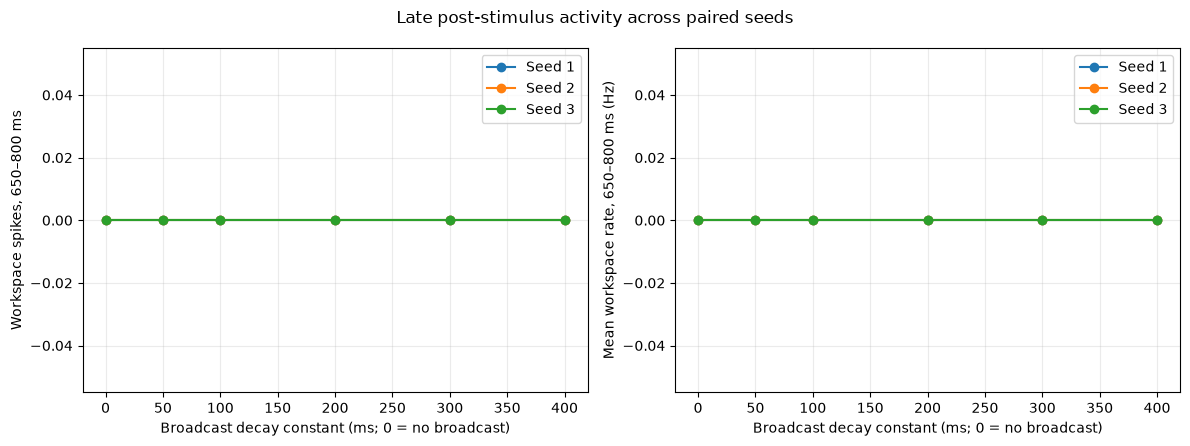

In [15]:
import gc
import pandas as pd
from tqdm.auto import tqdm

if network_mode == "full":
    broadcast_conductance_fixed_mS_cm2 = 0.005
    broadcast_tau_levels_ms = [50.0, 100.0, 200.0, 300.0, 400.0]
    tau_sweep_seeds = [1, 2, 3]
    sweep_duration = 800 * ms
    tau_sweep_rows = []

    conditions = [
        (seed, None) for seed in tau_sweep_seeds
    ] + [
        (seed, tau_ms)
        for seed in tau_sweep_seeds
        for tau_ms in broadcast_tau_levels_ms
    ]

    for seed, tau_ms in tqdm(conditions, desc="Extended broadcast decay sweep", unit="run"):
        is_baseline = tau_ms is None
        result = run_condition(
            True,
            pulse_current_value=float(pulse_current),
            interarea_conductance_value=interarea_total_conductance,
            tau_long_value=tau_long,
            rtm_seed_value=seed,
            enable_gnw_broadcast=not is_baseline,
            broadcast_conductance_value=(
                0 * msiemens / cm**2 if is_baseline
                else broadcast_conductance_fixed_mS_cm2 * msiemens / cm**2
            ),
            tau_gnw_broadcast_value=(
                tau_gnw_broadcast if is_baseline else tau_ms * ms
            ),
            run_duration_value=sweep_duration,
        )
        rates = rtm_spikes_to_rate_trace(
            result, n_areas, rate_window_ms, n_rtm_per_area
        )
        metrics = compute_ignition_metrics(
            rates,
            result["time_ms"],
            workspace_indices,
            threshold_hz=ignition_threshold_hz,
            min_duration_ms=ignition_min_duration_ms,
            onset_ms=stimulus_onset_ms,
        )
        time_values = np.asarray(result["time_ms"], dtype=float)
        early_post = (
            (time_values >= float(pulse_off / ms))
            & (time_values < float((pulse_off + 150 * ms) / ms))
        )
        late_post = (
            (time_values >= float((pulse_off + 150 * ms) / ms))
            & (time_values <= float(sweep_duration / ms))
        )
        spike_times = np.asarray(result["rtm_spike_times_ms"], dtype=float)
        workspace_spikes = np.isin(result["rtm_spike_area"], workspace_indices)
        early_spikes = workspace_spikes & (spike_times >= float(pulse_off / ms)) & (spike_times < float((pulse_off + 150 * ms) / ms))
        late_spikes = workspace_spikes & (spike_times >= float((pulse_off + 150 * ms) / ms)) & (spike_times <= float(sweep_duration / ms))
        tau_sweep_rows.append({
            "seed": seed,
            "broadcast_conductance_mS_cm2": 0.0 if is_baseline else broadcast_conductance_fixed_mS_cm2,
            "tau_gnw_broadcast_ms": 0.0 if is_baseline else tau_ms,
            "online_triggered": bool(result["gnw_broadcast_triggered"]),
            "ignited": bool(metrics["ignited"]),
            "ignition_latency_ms": metrics["latency_ms"],
            "mean_workspace_rate_500_650ms_hz": float(np.mean(metrics["workspace_rate_hz"][early_post])),
            "mean_workspace_rate_650_800ms_hz": float(np.mean(metrics["workspace_rate_hz"][late_post])),
            "workspace_spikes_500_650ms": int(np.count_nonzero(early_spikes)),
            "workspace_spikes_650_800ms": int(np.count_nonzero(late_spikes)),
            "max_workspace_mean_hz": float(np.max(metrics["workspace_rate_hz"])),
            "max_workspace_area_rate_hz": float(np.max(rates[:, workspace_indices])),
        })
        del result, rates, metrics
        gc.collect()

    broadcast_tau_sweep = pd.DataFrame(tau_sweep_rows).sort_values(
        ["seed", "tau_gnw_broadcast_ms"]
    ).reset_index(drop=True)
    print("Matched 800 ms baseline and broadcast decay-time conditions:")
    print(broadcast_tau_sweep.round(4).to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for seed in tau_sweep_seeds:
        seed_rows = broadcast_tau_sweep[broadcast_tau_sweep["seed"] == seed]
        axes[0].plot(
            seed_rows["tau_gnw_broadcast_ms"],
            seed_rows["workspace_spikes_650_800ms"],
            marker="o", label=f"Seed {seed}",
        )
        axes[1].plot(
            seed_rows["tau_gnw_broadcast_ms"],
            seed_rows["mean_workspace_rate_650_800ms_hz"],
            marker="o", label=f"Seed {seed}",
        )
    axes[0].set_xlabel("Broadcast decay constant (ms; 0 = no broadcast)")
    axes[0].set_ylabel("Workspace spikes, 650–800 ms")
    axes[1].set_xlabel("Broadcast decay constant (ms; 0 = no broadcast)")
    axes[1].set_ylabel("Mean workspace rate, 650–800 ms (Hz)")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle("Late post-stimulus activity across paired seeds")
    plt.tight_layout()
    plt.show()
else:
    print("Extended broadcast decay tuning requires network_mode='full'.")

## Scope of this GNW integration

- The notebook can run a 12-area tuning subnetwork or the full 40-area anatomical network; the current default is the full network.
- The workspace rule is mean RTM rate ≥20 Hz for at least 50 ms across F1, F2, F3, F4, 7a, and 7b.
- The selected baseline is pulse 110, FLN conductance 0.10 mS/cm², and `tau_long` 4 ms. A three-seed paired validation checks the baseline.
- The final section sweeps online global-broadcast conductance while holding the baseline fixed. It reuses the no-broadcast baseline and runs the three nonzero amplitudes.
- Each area contains four RTM cells and 40 WB cells. Plotted RTM rates are averaged across its four RTM cells.
- The reduced subnetwork omits input from non-selected areas; confirm conclusions in full mode.

In [17]:
broadcast_sweep.loc[
    broadcast_sweep["broadcast_conductance_mS_cm2"] == 0,
    "online_detector_enabled"
] = False

print(broadcast_sweep.round(4).to_string(index=False))

NameError: name 'broadcast_sweep' is not defined